<a href="https://colab.research.google.com/github/frandresst-wq/Proyecto-de-Ciencia-de-Datos/blob/main/S2_Notebook_Laboratorio_CDD_Soto_Franco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 2 — Calidad y preparación de tu conjunto de datos
**Ciencia de Datos · Semana 2 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA1 (cierre) · RA3 (transversal) |
| **Duración estimada** | 1 h asincrónica + 1 h de trabajo autónomo |
| **Insumo** | El conjunto de datos que elegiste en la semana 1 |
| **Producto** | Conjunto limpio + bitácora completada + avance versionado |
| **Estudiante** | Franco Soto Soto |

---

Este laboratorio **no trae los datos**: los traes tú. Todo lo que hagas aquí es el cuerpo de la **Entrega 1**, que rindes al cierre de esta semana.

Ten abierta en paralelo la planilla `S2_Bitacora_Decisiones_CDD.xlsx`. Escríbela **mientras trabajas**, no al final: reconstruir después por qué tomaste una decisión es mucho más difícil de lo que parece.

In [5]:
import pandas as pd
import numpy as np

RUTA = ''
SEMILLA = 20262
np.random.seed(SEMILLA)

ARCHIVO = 'ipc_base_20237baa955a44fe4eada201c196338fb3be.csv'
SEPARADOR = ';'

# Agregamos encoding='latin1' para evitar el error con caracteres en español
df = pd.read_csv(RUTA + ARCHIVO, sep=SEPARADOR, encoding='latin1')
print('Forma:', df.shape)
df.head(200)

Forma: (20262, 16)


,Año,Mes,División,Grupo,Clase,Subclase,Producto,Glosa,Ponderación,Índice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%),Incidencia 12 Meses (%)
0,2024,1,NaN,NaN,NaN,NaN,NaN,IPC General,NaN,"101,72","0,7","0,7","3,8",NaN,NaN,NaN
1,2024,1,1.0,NaN,NaN,NaN,NaN,ALIMENTOS Y BEBIDAS NO ALCOHÓLICAS,"22,15348","103,26",1,1,NaN,"0,215","0,215",NaN
2,2024,1,1.0,1.0,NaN,NaN,NaN,ALIMENTOS,"19,9127","103,14","0,8","0,8",NaN,"0,158","0,158",NaN
3,2024,1,1.0,1.0,1.0,NaN,NaN,"PAN, CEREALES, HARINAS Y PASTAS","4,29417","102,1",1,1,NaN,"0,045","0,045",NaN
4,2024,1,1.0,1.0,1.0,1.0,NaN,ARROZ,"0,22304","106,3","-0,1","-0,1",NaN,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2024,1,3.0,2.0,1.0,NaN,NaN,CALZADO,"1,01096","97,67",-1,-1,NaN,"-0,01","-0,01",NaN
196,2024,1,3.0,2.0,1.0,1.0,NaN,CALZADO PARA HOMBRES,"0,38681","96,16","-2,8","-2,8",NaN,"-0,011","-0,011",NaN
197,2024,1,3.0,2.0,1.0,1.0,1.0,ZAPATILLAS PARA HOMBRE,"0,27643","97,43","-2,4","-2,4",NaN,"-0,007","-0,007",NaN
198,2024,1,3.0,2.0,1.0,1.0,2.0,ZAPATOS PARA HOMBRE,"0,11038","92,96","-3,8","-3,8",NaN,"-0,004","-0,004",NaN


In [6]:
df.dtypes

,0
Año,int64
Mes,int64
División,float64
Grupo,float64
Clase,float64
Subclase,float64
Producto,float64
Glosa,object
Ponderación,object
Índice,object


Se evidencia que Ponderación, Indice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%) y Incidencia 12 Meses (%) Aparecen como object.



## Parte 1 · Diagnóstico de las cinco dimensiones

Antes de limpiar nada, hay que saber qué tienes. Completa la hoja **«Resumen de calidad»** de la bitácora con los resultados de esta parte.

++++++++ ¿Cómo evaluar estas dimensiones con Pandas?

1. **Completitud:**
Por ejemplo, df.isna().sum()
Cuenta los valores faltantes de cada columna.

2. **Exactitud:**
Por ejemplo, df.describe().T.round(2)
Permite identificar valores mínimos, máximos y rangos sospechosos en variables numéricas.

3. **Consistencia:**
Por ejemplo, (df['fecha_termino'] < df['fecha_inicio']).sum()
Cuenta los registros cuya fecha de término es anterior a la fecha de inicio, suponiendo que ambas columnas contienen fechas válidas.

4. **Unicidad:**
Por ejemplo, df.duplicated().sum()
Cuenta las filas duplicadas exactas, sin incluir la primera aparición.

5. **Oportunidad:**
Por ejemplo, df['fecha'].max()
Obtiene la fecha más reciente disponible en el conjunto de datos, siempre que la columna tenga un tipo de fecha adecuado.


### 1.1 Completitud

In [7]:
faltantes = df.isna().sum().to_frame('faltantes')
faltantes['pct'] = (faltantes['faltantes'] / len(df) * 100).round(2)
faltantes.sort_values('faltantes', ascending=False)

,faltantes,pct
Producto,10923,53.91
Incidencia 12 Meses (%),7389,36.47
Variación 12 Meses (%),7356,36.30
Subclase,5247,25.90
Clase,1980,9.77
Grupo,462,2.28
División,33,0.16
Ponderación,33,0.16
Incidencia Acumulada (%),33,0.16
Incidencia Mensual (%),33,0.16


### ✏️ Actividad 1.1

Elige la columna con más faltantes y averigua **si se reparten al azar o se concentran en algún grupo**. Usa `pd.crosstab` contra alguna columna categórica, como en el Ejercicio 1 del cuaderno resuelto.

Es la diferencia entre poder imputar y tener que declarar.

In [46]:
# Identificamos la columna con más nulos: 'Producto'
# Evaluamos si su ausencia se concentra según la 'División'
tabla_faltantes_producto = pd.crosstab(
    df['División'].fillna('General / No aplica'),
    df['Producto'].isna(),
    rownames=['División'],
    colnames=['Producto Faltante (NaN)']
)

tabla_faltantes_producto.columns = ['Presente (Tiene Producto)', 'Faltante (Es Categoría Superior)']
tabla_faltantes_producto['% Faltantes'] = (
    tabla_faltantes_producto['Faltante (Es Categoría Superior)'] /
    tabla_faltantes_producto.sum(axis=1) * 100
).round(2)

display(tabla_faltantes_producto)

,Presente (Tiene Producto),Faltante (Es Categoría Superior),% Faltantes
División,,,
1.0,2673,2145,44.52
2.0,198,429,68.42
3.0,759,561,42.50
4.0,495,858,63.41
5.0,1254,1320,51.28
6.0,759,759,50.00
7.0,825,1188,59.02
8.0,297,627,67.86
9.0,825,1419,63.24


### Conclusión del Análisis de Faltantes
Como se puede observar en la tabla cruzada, los valores faltantes en la columna `Producto` no ocurren al azar (no son perdidos aleatoriamente). Se concentran de manera estructural y sistemática en las filas que corresponden a agrupaciones de nivel superior del IPC (índices generales, divisiones, grupos o clases). Por lo tanto, no corresponde realizar una imputación de datos en esta columna, sino declarar que su ausencia es parte del diseño jerárquico del conjunto de datos.

### 1.2 Exactitud — rangos y valores imposibles

In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Año,20262.0,2024.91,0.79,2024.0,2024.0,2025.0,2026.0,2026.0
Mes,20262.0,6.09,3.31,1.0,3.0,6.0,9.0,12.0
División,20229.0,5.57,3.67,1.0,2.0,5.0,9.0,13.0
Grupo,19800.0,2.20,1.58,1.0,1.0,2.0,3.0,8.0
Clase,18282.0,2.46,2.13,1.0,1.0,1.0,3.0,9.0
Subclase,15015.0,1.81,1.24,1.0,1.0,1.0,2.0,7.0
Producto,9339.0,1.94,1.61,1.0,1.0,1.0,2.0,10.0


++++++++ No se observa valor centinela

### ✏️ Actividad 1.2

Mira los mínimos y máximos. **¿Hay valores imposibles para lo que la columna representa?** Busca en particular valores centinela: `-1`, `0`, `999`, `9999`, `-999`, o cadenas como `'S/I'`, `'NULL'`, `'sin dato'`.

Recuerda: un centinela numérico **no** se delata en los tipos de dato.

In [54]:
# Primero convertimos las columnas que deberían ser numéricas (reemplazando comas por puntos)
columnas_analizar = [
    'Ponderación', 'Índice', 'Variación Mensual (%)',
    'Variación Acumulada (%)', 'Variación 12 Meses (%)',
    'Incidencia Mensual (%)', 'Incidencia Acumulada (%)', 'Incidencia 12 Meses (%)'
]

df_temp = df.copy()
for col in columnas_analizar:
    df_temp[col] = pd.to_numeric(df_temp[col].astype(str).str.replace(',', '.'), errors='coerce')

# Ahora buscamos los valores centinela en todo el DataFrame numérico
centinelas = [-1, 0, 999, 9999, -999]
columnas_numericas = df_temp.select_dtypes(include='number').columns

print('=== Búsqueda de Valores Centinela ===')
for col in columnas_numericas:
    print(f'\nColumna: {col}')
    for valor in centinelas:
        cantidad = (df_temp[col] == valor).sum()
        if cantidad > 0:
            print(f'  -> Valor centinela {valor} encontrado: {cantidad} veces')

=== Búsqueda de Valores Centinela ===

Columna: Año

Columna: Mes

Columna: División

Columna: Grupo

Columna: Clase

Columna: Subclase

Columna: Producto

Columna: Ponderación

Columna: Índice

Columna: Variación Mensual (%)
  -> Valor centinela -1 encontrado: 238 veces
  -> Valor centinela 0 encontrado: 2689 veces

Columna: Variación Acumulada (%)
  -> Valor centinela -1 encontrado: 118 veces
  -> Valor centinela 0 encontrado: 734 veces

Columna: Variación 12 Meses (%)
  -> Valor centinela -1 encontrado: 46 veces
  -> Valor centinela 0 encontrado: 235 veces

Columna: Incidencia Mensual (%)
  -> Valor centinela 0 encontrado: 5218 veces

Columna: Incidencia Acumulada (%)
  -> Valor centinela 0 encontrado: 2046 veces

Columna: Incidencia 12 Meses (%)
  -> Valor centinela 0 encontrado: 724 veces


Se entiende que estos datos representan la variacion mensual en porcenje por ende puede  existir numero negativo y 0, son valores reales.

### 1.3 Consistencia — reglas cruzadas

+++++++ La consistencia es una dimensión de la calidad de datos que evalúa si la información mantiene coherencia entre sus valores, columnas, registros y reglas del conjunto de datos.

En otras palabras, busca detectar datos que se contradicen entre sí.

Ejemplos:\
Un trabajador tiene 15 años y registra 20 años de experiencia.\
Una estación pertenece a la comuna de Concepción en un registro y a Valdivia en otro.\
Una fecha de término es anterior a la fecha de inicio.\
Un producto tiene precio total de $50.000, pero cantidad 10 y precio unitario $8.000.

### ✏️ Actividad 1.3

Escribe **dos reglas de consistencia** que tu conjunto debería cumplir y verifícalas. Ejemplos:

- «La fecha de término no puede ser anterior a la de inicio.»
- «Si el estado es *cerrado*, el monto vigente debe estar vacío.»
- «La suma de las partes debe igualar el total.»

Estas reglas no salen de los datos: salen de entender qué representan.

In [9]:
# Regla 1 de Consistencia:
# a) Integridad jerárquica: Ningún código de nivel inferior puede existir si su nivel padre es nulo (NaN).
# b) Suma de ponderaciones: La suma de 'Ponderación' por cada nivel jerárquico en cada mes debe ser 100.0%.

df_cons = df.copy()
cols_num_temp = ['Ponderación', 'Índice', 'Variación Mensual (%)', 'Variación Acumulada (%)',
                 'Incidencia Mensual (%)', 'Incidencia Acumulada (%)']
for c in cols_num_temp:
    df_cons[c] = pd.to_numeric(df_cons[c].astype(str).str.replace(',', '.'), errors='coerce')

# Verificación a): Hijos sin padre en la jerarquía División > Grupo > Clase > Subclase > Producto
inconsistencias_jerarquia = (
    (df_cons['Producto'].notna() & df_cons['Subclase'].isna()) |
    (df_cons['Subclase'].notna() & df_cons['Clase'].isna()) |
    (df_cons['Clase'].notna() & df_cons['Grupo'].isna()) |
    (df_cons['Grupo'].notna() & df_cons['División'].isna())
).sum()
print('Inconsistencias jerárquicas (código hijo sin código padre):', inconsistencias_jerarquia)

# Verificación b): Suma de Ponderación en bruto vs. separada por nivel jerárquico
suma_bruta_mes = df_cons.groupby(['Año', 'Mes'])['Ponderación'].sum().iloc[0].round(2)
print('Suma bruta de Ponderación en un mes (sin aislar nivel jerárquico):', suma_bruta_mes, '%')

cond_niveles = [
    df_cons['División'].isna(),
    df_cons['División'].notna() & df_cons['Grupo'].isna(),
    df_cons['Grupo'].notna() & df_cons['Clase'].isna(),
    df_cons['Clase'].notna() & df_cons['Subclase'].isna(),
    df_cons['Subclase'].notna() & df_cons['Producto'].isna(),
    df_cons['Producto'].notna()
]
nom_niveles = ['0_IPC_General', '1_Division', '2_Grupo', '3_Clase', '4_Subclase', '5_Producto']
df_cons['nivel_temp'] = np.select(cond_niveles, nom_niveles, default='Otro')

tabla_pond_nivel = (
    df_cons[df_cons['nivel_temp'] != '0_IPC_General']
    .groupby(['Año', 'Mes', 'nivel_temp'])['Ponderación']
    .sum().unstack().round(4)
)
print('\nSuma de Ponderación separada por nivel jerárquico (primeros 3 meses):')
display(tabla_pond_nivel.head(3))

Inconsistencias jerárquicas (código hijo sin código padre): 0
Suma bruta de Ponderación en un mes (sin aislar nivel jerárquico): 500.0 %

Suma de Ponderación separada por nivel jerárquico (primeros 3 meses):


nivel_temp  1_Division  2_Grupo  3_Clase  4_Subclase  5_Producto
Año  Mes                                                        
2024 1           100.0    100.0    100.0       100.0       100.0
     2           100.0    100.0    100.0       100.0       100.0
     3           100.0    100.0    100.0       100.0       100.0

**Conclusión Regla 1:** No existen registros huérfanos en la jerarquía de códigos (`0` inconsistencias). Sin embargo, si se suma la columna `Ponderación` en un mes sin filtrar el nivel jerárquico, el total da **500,0%** porque en la misma tabla conviven los 5 niveles desagregados (`División`, `Grupo`, `Clase`, `Subclase` y `Producto`), cada uno de los cuales suma exactamente **100,0%**. Esto demuestra que en la etapa de preparación es obligatorio crear un atributo que identifique el nivel jerárquico antes de realizar cualquier suma o análisis.

In [10]:
# Regla 2 de Consistencia:
# a) En cada mes de Enero (Mes == 1), la Variación Acumulada (%) debe ser igual a la Variación Mensual (%).
# b) Cada categoría textual ('Glosa') debería tener una única Ponderación fija en la canasta 2023.

enero = df_cons[df_cons['Mes'] == 1]
incons_enero = (enero['Variación Mensual (%)'] != enero['Variación Acumulada (%)']).sum()
print('Inconsistencias en Enero (Variación Mensual != Variación Acumulada):', incons_enero)

# Verificación de unicidad de Ponderación por Glosa
pond_por_glosa = df_cons.groupby('Glosa')['Ponderación'].nunique()
glosas_inconsistentes = pond_por_glosa[pond_por_glosa > 1]
print('\nGlosas que presentan más de una Ponderación distinta:', len(glosas_inconsistentes))
display(
    df_cons[df_cons['Glosa'].isin(glosas_inconsistentes.index) & (df_cons['Año'] == 2024) & (df_cons['Mes'] == 1)]
    [['División', 'Grupo', 'Clase', 'Subclase', 'Producto', 'nivel_temp', 'Glosa', 'Ponderación']]
)

Inconsistencias en Enero (Variación Mensual != Variación Acumulada): 0

Glosas que presentan más de una Ponderación distinta: 5


,División,Grupo,Clase,Subclase,Producto,nivel_temp,Glosa,Ponderación
167,3.0,1.0,NaN,NaN,NaN,2_Grupo,VESTUARIO,1.88944
168,3.0,1.0,1.0,NaN,NaN,3_Clase,VESTUARIO,1.75721
218,4.0,2.0,2.0,NaN,NaN,3_Clase,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.10487
219,4.0,2.0,2.0,1.0,NaN,4_Subclase,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.10487
220,4.0,2.0,2.0,1.0,1.0,5_Producto,SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA,1.03569
248,5.0,1.0,NaN,NaN,NaN,2_Grupo,MUEBLES Y ARTÍCULOS PARA EL HOGAR,1.09351
249,5.0,1.0,1.0,NaN,NaN,3_Clase,MUEBLES Y ARTÍCULOS PARA EL HOGAR,1.07218
303,5.0,5.0,2.0,NaN,NaN,3_Clase,HERRAMIENTAS MANUALES Y ACCESORIOS,0.10760
304,5.0,5.0,2.0,1.0,NaN,4_Subclase,HERRAMIENTAS MANUALES Y ACCESORIOS,0.03201
305,5.0,5.0,2.0,1.0,1.0,5_Producto,HERRAMIENTAS MANUALES Y ACCESORIOS,0.03201


**Conclusión Regla 2:** La coherencia temporal en los meses de enero se cumple al 100% (`0` inconsistencias). En cambio, al cruzar `Glosa` con `Ponderación`, se detectan **5 glosas** (`VESTUARIO`, `SERVICIOS PARA EL MANTENIMIENTO DE LA VIVIENDA`, `MUEBLES Y ARTÍCULOS PARA EL HOGAR`, `HERRAMIENTAS MANUALES Y ACCESORIOS` y `MEDICAMENTOS`) que tienen **dos ponderaciones distintas** porque el mismo nombre se utiliza en dos niveles jerárquicos diferentes (por ejemplo, `VESTUARIO` como Grupo 3.1 pesa `1,88944%` y como Clase 3.1.1 pesa `1,75721%`). Por lo tanto, no basta con agrupar por `Glosa`: se debe desambiguar cada fila mediante su código y nivel jerárquico.

### 1.4 Unicidad

In [11]:
print('Duplicados exactos:', df.duplicated().sum())
# Si tu conjunto tiene una columna identificadora, revísala también:
# print('ID repetidos:', df['TU_ID'].duplicated().sum())

Duplicados exactos: 0


No se detectactan duplicados

### ✏️ Actividad 1.4

Construye una **clave normalizada** (sin espacios, en mayúsculas, sin tildes) con las columnas que deberían identificar un registro, y cuenta los casi-duplicados.

+++++++ En este conjunto de datos del IPC, podemos utilizar las columnas:
- Glosa: Descripción de producto del IPC
- Producto: Código de producto de canasta IPC
- Subclase: Código de subclase de canasta IPC
- Clase: Código de clase de canasta IPC
- Año: Año de la medición
- Mes: Mes de la medición

La combinación de los datos de estas columnas puede utilizarse como clave, suponiendo que existe 1 tipo de producto de cada clase/subclase al mes en el año correspondiente.

In [12]:
def normalizar_texto(serie):
    return (serie.astype(str).str.strip().str.upper()
                 .str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('ascii'))

# Tu código aquí
# Crear clave normalizada
df['clave'] = (
    normalizar_texto(df['Glosa']) + '_' +
    normalizar_texto(df['Producto']) + '_' +
    normalizar_texto(df['Subclase']) + '_' +
    normalizar_texto(df['Clase']) + '_' +
    normalizar_texto(df['Año']) + '_' +
    df['Mes'].astype(str).str[:10]

)
# Contar registros con claves repetidas
print('Casi-duplicados:', df['clave'].duplicated().sum())

Casi-duplicados: 0


Si bien en el archivo .csv existen datos que son exatamente los mismos pero varian en el valor de 1 sola fila para utilizar la informacion de esta tabla es necesario aislar la informacion con la que se quiere trabajar. Los datos parecen casi idénticos en algunas filas porque el archivo del Índice de Precios al Consumidor (IPC) utiliza una estructura jerárquica de agregación (División > Grupo > Clase > Subclase > Producto). Cuando una categoría de un nivel superior (como una "Subclase") está compuesta por un único elemento en el nivel inferior ("Producto"), los valores estadísticos se repiten porque representan exactamente el mismo ítem.
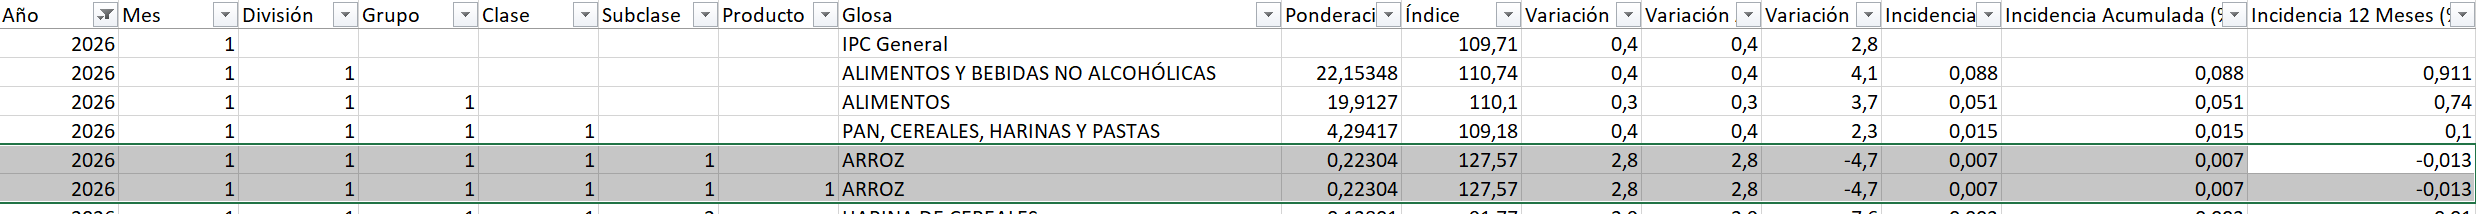

Para trabajar con esta base de datos correctamente sin sufrir problemas de duplicidad, se debe filtrar la información por un nivel específico antes de hacer cualquier cálculo. En resumen: no se debe eliminar estas filas con herramientas de "quitar duplicados", ya que se romperia la estructura de la tabla. Lo correcto es segmentar y aislar el nivel jerárquico que se quiera analizar.

In [13]:
#Cuales son?
duplicados = df[df['clave'].duplicated(keep=False)]
display(duplicados.sort_values('clave'))

,Año,Mes,División,Grupo,Clase,Subclase,Producto,Glosa,Ponderación,Índice,Variación Mensual (%),Variación Acumulada (%),Variación 12 Meses (%),Incidencia Mensual (%),Incidencia Acumulada (%),Incidencia 12 Meses (%),clave


No existen duplicados

### 1.5 Oportunidad

In [ ]:
# Si tienes alguna columna de fecha, ¿cuál es el registro más reciente?
# ¿El conjunto está vigente para la pregunta que quieres responder?


+++++++ La oportunidad es la dimensión de calidad que evalúa si los datos están disponibles y actualizados en el momento en que se necesitan para realizar un análisis o tomar decisiones.\
¿Los datos llegan a tiempo y están suficientemente actualizados para ser útiles?\


In [15]:
# Creamos una serie de fechas temporales combinando Año y Mes
fechas_temp = pd.to_datetime(df['Año'].astype(str) + '-' + df['Mes'].astype(str) + '-01')

print('Primera medición:', fechas_temp.min().strftime('%Y-%m'))
print('Última medición:', fechas_temp.max().strftime('%Y-%m'))
print('Fecha actual:', pd.Timestamp.today().date())

Primera medición: 2024-01
Última medición: 2026-09
Fecha actual: 2026-10-25


In [16]:
# ¿Cuántos días han pasado desde la última medición?
# Usamos la serie de fechas calculada 'fechas_temp' que combina Año y Mes
ultima_fecha = fechas_temp.max()
hoy = pd.Timestamp.today().normalize()

dias = (hoy - ultima_fecha).days

print('Última fecha de medición:', ultima_fecha.strftime('%Y-%m-%d'))
print('Días desde la última medición:', dias)

Última fecha de medición: 2026-09-01
Días desde la última medición: 54


---
## Parte 2 · Limpieza, decisión por decisión

Ahora corriges. **Regla del laboratorio: cada celda de esta parte tiene su fila en la bitácora.** Si aplicas una transformación que no registraste, no cuenta.

Recuerda las tres decisiones legítimas: **Corregir**, **Descartar** o **Declarar como limitación**.

### ✏️ Actividad 2.1 — Centinelas a faltantes

+++++ En la Parte 1 se detectaron 18 valores -999 en la columna pm10. Ahora corresponde corregirlos, reemplazándolos por NaN, ya que una concentración de material particulado no puede ser negativa.

In [ ]:
# Tu código aquí
# Reemplazar valores centinela por NaN
df['pm10'] = df['pm10'].replace(-999, np.nan)

# Verificar los faltantes
print(df[['pm10', 'pm25']].isna().sum())

pm10    18
pm25    35
dtype: int64


### ✏️ Actividad 2.2 — Normalización de categorías

Normaliza mecánicamente y después revisa lo que queda: los plurales, las abreviaturas y los sinónimos necesitan un diccionario de equivalencias que escribes tú.

+++++++  En este conjunto de datos de calidad del aire, podemos normalizar las columnas categóricas **estacion, comuna, region y validado**.

El objetivo es unificar las categorías que representan lo mismo, pero están escritas de manera diferente.

In [ ]:
# Tu código aquí
# Normalización Mecánica
# Se eliminan espacios, se unifican mayúsculas y se quitan tildes.
# Normalizar categorías
columnas = ['estacion', 'comuna', 'region', 'validado']

for col in columnas:
    df[col] = normalizar_texto(df[col]) #la función normalizar_texto está arriba, en la actividad 1.4

# Revisar las categorías resultantes
for col in columnas:
    print('\nColumna:', col)
    print(df[col].unique())


Columna: estacion
['LOS ANGELES ORIENTE' 'CORONEL NORTE' 'OSORNO ENTRE LAGOS' 'KINGSTON'
 'TEMUCO PADRE LAS CASAS' 'TALCAHUANO' 'COYHANCO' 'VALDIVIA CENTRO']

Columna: comuna
['LOS ANGELES' 'CORONEL' 'OSORNO' 'CONCEPCION' 'TEMUCO' 'TALCAHUANO'
 'CHILLAN' 'VALDIVIA']

Columna: region
['BIOBIO' 'LOS LAGOS' 'ARAUCANIA' 'NUBLE' 'LOS RIOS']

Columna: validado
['SI']


In [ ]:
# Categorías que quedan
for col in columnas:
    print('\n',col, ':', df[col].nunique(), 'categorías')
    print(df[col].value_counts())


 estacion : 8 categorías
estacion
TALCAHUANO                94
OSORNO ENTRE LAGOS        93
KINGSTON                  92
LOS ANGELES ORIENTE       92
TEMUCO PADRE LAS CASAS    92
VALDIVIA CENTRO           91
CORONEL NORTE             90
COYHANCO                  90
Name: count, dtype: int64

 comuna : 8 categorías
comuna
TALCAHUANO     94
OSORNO         93
CONCEPCION     92
LOS ANGELES    92
TEMUCO         92
VALDIVIA       91
CORONEL        90
CHILLAN        90
Name: count, dtype: int64

 region : 5 categorías
region
BIOBIO       368
LOS LAGOS     93
ARAUCANIA     92
LOS RIOS      91
NUBLE         90
Name: count, dtype: int64

 validado : 1 categorías
validado
SI    734
Name: count, dtype: int64


++++++ La categoría validado no se pudo normalizar mecánicamente, porque son cadenas distintas: S, N, SI, NO\
Se crea un diccionario de equivalencia

In [ ]:
equivalencias = {
    'S': 'SI',
    'N': 'NO'
}

df['validado'] = df['validado'].replace(equivalencias)
# Mostrar categorías y cantidades
print(df['validado'].value_counts())

print(df['validado'].unique())

display(df['validado'].value_counts().to_frame('Cantidad'))

validado
SI    734
Name: count, dtype: int64
['SI']


,Cantidad
validado,
SI,734


### ✏️ Actividad 2.3 — Duplicados

+++++  En la Parte 1 se detectaron 14 registros duplicados exactos en el conjunto de datos de calidad del aire.\
Ahora se debe decidir si corresponde corregir, descartar o declarar como limitación.\
En este caso, podemos descartar los duplicados exactos, ya que contienen la misma información y mantenerlos podría alterar los resultados del análisis.

In [ ]:
# Tu código aquí
# Código para eliminar duplicados
# Contar duplicados antes
print('Duplicados antes:', df.duplicated().sum())

# Eliminar duplicados exactos
df = df.drop_duplicates().copy()

# Verificar después
print('Duplicados después:', df.duplicated().sum())

# Mostrar cantidad de registros
print('Registros restantes:', len(df))

Duplicados antes: 14
Duplicados después: 0
Registros restantes: 720


In [ ]:
duplicados = df[df.duplicated(
    subset=['estacion', 'fecha'],
    keep=False
)]

display(duplicados.sort_values(['estacion', 'fecha']))

,id_registro,estacion_id,estacion,comuna,region,fecha,pm25,pm10,temperatura_c,humedad_pct,validado,clave


In [ ]:
print('Duplicados exactos:', df.duplicated().sum())

print('Duplicados por estación y fecha:',
      df.duplicated(subset=['estacion', 'fecha']).sum())

Duplicados exactos: 0
Duplicados por estación y fecha: 0


+++++++++ Al verificar la unicidad mediante la combinación de estación y fecha, no se encontraron registros duplicados en el conjunto de datos actual.\
Esto indica que cada estación presenta un único registro por fecha. Por lo tanto, no es necesario eliminar registros adicionales según este criterio.

### ✏️ Actividad 2.4 — Tipos de dato

Convierte a numérico lo que deba ser numérico y a fecha lo que deba ser fecha. Si hay formatos mixtos, prueba formatos explícitos en orden en vez de dejar que pandas adivine.

+++++ En este conjunto de datos de calidad del aire, se debe verificar que las columnas numéricas sean realmente numéricas y que fecha tenga el tipo datetime.

In [ ]:
# Tu código aquí
# Convertir columnas numéricas
columnas = ['pm25', 'pm10', 'temperatura_c', 'humedad_pct']
for col in columnas:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '.'),
        errors='coerce'
    )

# Convertir fechas con formatos mixtos
fechas = df['fecha'].astype(str).str.strip()
fecha1 = pd.to_datetime(
    fechas, format='%Y-%m-%d', errors='coerce'
)

fecha2 = pd.to_datetime(
    fechas, format='%d/%m/%Y', errors='coerce'
)
df['fecha'] = fecha1.fillna(fecha2)

# Mostrar tipos de datos
print(df.dtypes)

id_registro              object
estacion_id               int64
estacion                 object
comuna                   object
region                   object
fecha            datetime64[ns]
pm25                    float64
pm10                    float64
temperatura_c           float64
humedad_pct             float64
validado                 object
clave                    object
dtype: object


In [ ]:
# comprobar si alguna conversión produjo valores NaN adicionales
print( df.isna().sum())

id_registro       0
estacion_id       0
estacion          0
comuna            0
region            0
fecha             0
pm25             34
pm10             18
temperatura_c     0
humedad_pct       0
validado          0
clave             0
dtype: int64


++++++  Después de realizar las transformaciones de tipos de datos, el conjunto presenta 34 valores faltantes en pm25 y 18 en pm10, mientras que las demás columnas no presentan ausencias.\
La disminución de 35 a 34 faltantes en pm25 podría deberse a la eliminación de registros duplicados realizada anteriormente.

### ✏️ Actividad 2.5 — Atípicos

Identifica los valores extremos y **pronúnciate sobre cada grupo**: ¿error de registro o fenómeno real?

Cruza la variable con otra que te permita juzgar plausibilidad, como en el Ejercicio 8. No elimines atípicos solo por serlo.

++++++ En este conjunto de datos de calidad del aire, se deben identificar valores extremos en pm25, pm10, temperatura_c y humedad_pct, y determinar si podrían ser errores de registro o fenómenos reales.\
Anteriormente se encontró un valor máximo de 586,7 en pm25, que merece una revisión especial.

++++++ Se pueden identificar los valores atípicos con el método IQR. el cual identifica valores que se alejan considerablemente del rango central de los datos (un valor se considera atípico si queda muy por debajo o por encima del rango donde se concentra la mayoría de los datos).\
Q1 (primer cuartil, 25 %): el valor por debajo del cual se encuentra aproximadamente el 25 % de los datos.\
Q3 (tercer cuartil, 75 %): el valor por debajo del cual se encuentra aproximadamente el 75 % de los datos.\
El **rango intercuartílico** (Interquartile Range, IQR),  representa la amplitud del 50 % central de los datos. Al usar el tramo entre Q1 y Q3, el IQR es menos sensible a valores extremos que otras medidas, como el rango total.\
Es posible definir los **límites** para identificar posibles atípicos:\
Límite inferior: valores menores que Q1 - 1.5 × IQR.\
Límite superior: valores mayores que Q3 + 1.5 × IQR.\
El factor 1.5 es una convención habitual del método de Tukey. Es una regla estadística práctica: señala observaciones inusualmente alejadas del centro, pero no demuestra por sí sola que sean errores.

In [ ]:
# Tu código aquí
# Identificar valores atípicos
columnas = ['pm25', 'pm10', 'temperatura_c', 'humedad_pct']

for col in columnas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    inferior = Q1 - 1.5 * IQR
    superior = Q3 + 1.5 * IQR

    atipicos = df[
        (df[col] < inferior) | (df[col] > superior)
    ]

    print('\nVariable:', col)
    print('Límite inferior:', round(inferior, 2))
    print('Límite superior:', round(superior, 2))
    print('Cantidad de atípicos:', len(atipicos))


Variable: pm25
Límite inferior: 15.05
Límite superior: 98.45
Cantidad de atípicos: 16

Variable: pm10
Límite inferior: 26.79
Límite superior: 179.89
Cantidad de atípicos: 5

Variable: temperatura_c
Límite inferior: 2.45
Límite superior: 19.65
Cantidad de atípicos: 3

Variable: humedad_pct
Límite inferior: 52.95
Límite superior: 99.15
Cantidad de atípicos: 1


+++++++ Cruzar los valores extremos con estación y fecha.\
Como el ejercicio pide comprobar su plausibilidad, podemos revisar las mediciones extremas de pm25 junto con la estación, fecha y pm10.

In [ ]:
# Identificar valores extremos de pm25
Q1 = df['pm25'].quantile(0.25)
Q3 = df['pm25'].quantile(0.75)
IQR = Q3 - Q1

limite = Q3 + 1.5 * IQR

atipicos = df[df['pm25'] > limite]

# Mostrar información relacionada
display(atipicos[['estacion', 'fecha', 'pm25', 'pm10']
                 ].sort_values('pm25', ascending=False)
)

,estacion,fecha,pm25,pm10
68,LOS ANGELES ORIENTE,2026-04-27,586.7,126.7
167,TEMUCO PADRE LAS CASAS,2026-06-10,544.4,113.7
344,LOS ANGELES ORIENTE,2026-06-22,499.9,122.2
151,COYHANCO,2026-04-11,497.0,NaN
220,OSORNO ENTRE LAGOS,2026-04-21,477.3,112.0
699,LOS ANGELES ORIENTE,2026-05-21,446.4,113.6
174,KINGSTON,2026-04-14,421.0,78.0
333,VALDIVIA CENTRO,2026-05-01,358.9,105.3
585,OSORNO ENTRE LAGOS,2026-04-12,329.7,97.0
511,TALCAHUANO,2026-04-24,292.2,78.7


Tu conclusión sobre los atípicos:\
+++++ Al cruzar los valores atípicos de pm25 con las estaciones, fechas y mediciones de pm10, se observa que los valores extremos aparecen en distintas estaciones y fechas, sin una concentración temporal evidente.

Se identificaron mediciones muy elevadas de pm25, alcanzando un máximo de 586,7. Además, en varios registros, pm25 supera considerablemente a pm10, lo que representa una posible inconsistencia, ya que PM2.5 corresponde a una fracción del material particulado PM10.

Por lo tanto, estos valores podrían corresponder a errores de medición o registro, aunque no es posible confirmarlo con la información disponible.

Se decide mantener los registros y declarar estos valores como una limitación del análisis, hasta contar con información que permita determinar si corresponden a errores o fenómenos reales de contaminación.\
En la tabla resultante, 12 de los 14 valores extremos mostrados de pm25 superan sus correspondientes valores de pm10; otro registro tiene pm10 faltante. Esto refuerza la necesidad de revisar la validez de esas mediciones antes de utilizarlas en el análisis.



---
## Parte 3 · Transformación y nuevos atributos

Preparar no es solo corregir: también es **construir** lo que el análisis va a necesitar.

### ✏️ Actividad 3.1 — Un atributo derivado

Crea **al menos una variable nueva** a partir de las existentes, que aporte a tu pregunta analítica. Ejemplos: una razón entre dos columnas, la antigüedad en años a partir de una fecha, un tramo a partir de un valor continuo.

Explica en la celda siguiente por qué esa variable ayuda a responder tu pregunta.

+++++++ Para este conjunto de datos de calidad del aire, se propone crear una variable llamada mes, a partir de la columna fecha.

Esta variable permitirá analizar cómo cambian las concentraciones de pm25 entre abril, mayo y junio de 2026.

In [ ]:
# Tu código aquí
# Crear una nueva variable a partir de fecha
df['mes'] = df['fecha'].dt.month  #este dt accede al mes (month) de cada fecha

# Mostrar los resultados
display(df[['estacion', 'fecha', 'mes', 'pm25']].head(10))

,estacion,fecha,mes,pm25
0,LOS ANGELES ORIENTE,2026-06-26,6,77.1
1,CORONEL NORTE,2026-04-05,4,31.6
2,OSORNO ENTRE LAGOS,2026-06-21,6,63.5
3,KINGSTON,2026-05-31,5,48.1
4,TEMUCO PADRE LAS CASAS,2026-05-22,5,85.0
5,TALCAHUANO,2026-06-16,6,41.3
6,OSORNO ENTRE LAGOS,2026-05-01,5,NaN
7,CORONEL NORTE,2026-05-31,5,52.0
8,LOS ANGELES ORIENTE,2026-05-12,5,77.6
9,TEMUCO PADRE LAS CASAS,2026-06-18,6,63.9


Se utilizará  esta nueva variable mes en el análisis.
Podemos calcular el promedio de pm25 por me:

In [ ]:
tabla = df.groupby('mes')['pm25'].mean().round(2)
#Esto permitirá identificar qué mes presenta mayores concentraciones promedio de material particulado fino.
display(tabla)

,pm25
mes,
4,61.21
5,59.81
6,65.99


Por qué esta variable aporta a mi pregunta:\
+++++ La variable mes permite agrupar las mediciones de calidad del aire por períodos y analizar cómo varían las concentraciones de PM2.5 a lo largo del tiempo.

Esto facilita comparar los niveles de contaminación entre abril, mayo y junio, identificar posibles tendencias temporales y determinar en qué meses se presentan mayores concentraciones.


### ✏️ Actividad 3.2 — Normalización o codificación

Si tu conjunto tiene variables numéricas en escalas muy distintas, o categóricas que necesitarás codificar en la semana 4, déjalas preparadas aquí.

In [ ]:
# Tu código aquí. Referencia:
# from sklearn.preprocessing import StandardScaler, MinMaxScaler
# df_cod = pd.get_dummies(df, columns=['TU_COLUMNA_CATEGORICA'], drop_first=True)


+++++ En este conjunto de datos hay variables numéricas (pm25, pm10, temperatura_c, humedad_pct) y categóricas (estacion, comuna, region, validado).\
Para esta actividad es posible aplicar dos transformaciones:
1. Normalización: llevar las variables numéricas a una escala común.
2. Codificación: transformar variables categóricas en columnas numéricas.

In [ ]:
#Se normalizarán las variables numéricas
#Se utilizará MinMaxScaler, que transforma los valores a una escala entre 0 y 1
from sklearn.preprocessing import MinMaxScaler

# Seleccionar columnas numéricas
columnas = ['pm25', 'pm10', 'temperatura_c', 'humedad_pct']

# Crear el normalizador
scaler = MinMaxScaler()

# Crear copia para conservar los datos originales
df_norm = df.copy()

# Normalizar
df_norm[columnas] = scaler.fit_transform(df[columnas])

# Mostrar resultado
display(df_norm[columnas].head(10))

,pm25,pm10,temperatura_c,humedad_pct
0,0.111886,0.739787,0.458537,0.157350
1,0.032590,0.163962,0.614634,0.304348
2,0.088184,0.496363,0.321951,0.668737
3,0.061345,0.317292,0.697561,0.505176
4,0.125654,0.780078,0.556098,0.666667
5,0.049495,0.344152,0.317073,0.782609
6,NaN,0.605484,0.678049,0.111801
7,0.068142,0.459429,0.531707,0.426501
8,0.112757,0.635702,0.692683,0.811594
9,0.088881,0.489647,0.448780,0.890269


+++++ En este conjunto de datos existen valores extremos de pm25. MinMaxScaler es sensible a ellos, por lo que conviene conservar los valores originales y evaluar el efecto de la transformación.

++++ Se codificará la variable categórica estacion utilizando pd.get_dummies().

In [ ]:
# Codificar estaciones
df_cod = pd.get_dummies(
    df,
    columns=['estacion'],
    drop_first=True,
    dtype=int
)

# Mostrar columnas creadas
display(df_cod.filter(like='estacion_').head(10))


,estacion_id,estacion_COYHANCO,estacion_KINGSTON,estacion_LOS ANGELES ORIENTE,estacion_OSORNO ENTRE LAGOS,estacion_TALCAHUANO,estacion_TEMUCO PADRE LAS CASAS,estacion_VALDIVIA CENTRO
0,2,0,0,1,0,0,0,0
1,8,0,0,0,0,0,0,0
2,6,0,0,0,1,0,0,0
3,1,0,1,0,0,0,0,0
4,5,0,0,0,0,0,1,0
5,4,0,0,0,0,1,0,0
6,6,0,0,0,1,0,0,0
7,8,0,0,0,0,0,0,0
8,2,0,0,1,0,0,0,0
9,5,0,0,0,0,0,1,0


+++++++ Se prepararon las variables numéricas y categóricas para futuros análisis. Las mediciones de calidad del aire se normalizaron mediante MinMaxScaler, llevándolas a una escala común entre 0 y 1.

Además, se codificó la variable estación mediante get_dummies, transformando sus categorías en columnas numéricas para usarlas en futuros modelos que requieran números.

Estas transformaciones permiten preparar el conjunto de datos para aplicar métodos estadísticos y modelos de aprendizaje automático, conservando los datos originales para futuras comparaciones.

---
## Parte 4 · El flujo como función reutilizable

Junta todo lo anterior en **una sola función**. Esto es lo que evalúa el RA3 y lo que se revisa en la Sección A de la Entrega Final: que tu limpieza se pueda volver a ejecutar de principio a fin.

In [ ]:
def limpiar(ruta, sep=SEPARADOR, semilla=SEMILLA):
    """Flujo completo de limpieza de mi conjunto. Devuelve (df_limpio, informe)."""
    np.random.seed(semilla)
    d = pd.read_csv(ruta, sep=sep)
    informe = {'filas_iniciales': len(d)}

    # 1 · centinelas
    # 2 · categorías
    # 3 · duplicados
    # 4 · tipos
    # 5 · atípicos
    # 6 · atributos derivados

    informe['filas_finales'] = len(d)
    return d, informe


limpio, informe = limpiar(RUTA + ARCHIVO)
print(informe)

{'filas_iniciales': 734, 'filas_finales': 734}


In [ ]:

def limpiar(ruta, sep=SEPARADOR, semilla=SEMILLA):
    """Flujo completo de limpieza. Devuelve (df_limpio, informe)."""

    np.random.seed(semilla)
    d = pd.read_csv(ruta, sep=sep)
    informe = {'filas_iniciales': len(d)}

    # 1 · Centinelas
    d['pm10'] = pd.to_numeric(
        d['pm10'].astype(str).str.replace(',', '.'),
        errors='coerce'
    )
    informe['centinelas_pm10'] = (d['pm10'] == -999).sum()
    d['pm10'] = d['pm10'].replace(-999, np.nan)

    # 2 · Categorías
    columnas = ['estacion', 'comuna', 'region', 'validado']

    for col in columnas:
        d[col] = normalizar_texto(d[col])

    equivalencias = {'S': 'SI', 'N': 'NO'}
    d['validado'] = d['validado'].replace(equivalencias)

    # 3 · Duplicados
    informe['duplicados'] = d.duplicated().sum()
    d = d.drop_duplicates().copy()

    # 4 · Tipos
    columnas = ['pm25', 'pm10', 'temperatura_c', 'humedad_pct']

    for col in columnas:
        d[col] = pd.to_numeric(
            d[col].astype(str).str.replace(',', '.'),
            errors='coerce'
        )

    fechas = d['fecha'].astype(str).str.strip()

    fecha1 = pd.to_datetime(
        fechas, format='%Y-%m-%d', errors='coerce'
    )
    fecha2 = pd.to_datetime(
        fechas, format='%d/%m/%Y', errors='coerce'
    )

    d['fecha'] = fecha1.fillna(fecha2)

    # 5 · Atípicos
    informe['atipicos'] = {}

    for col in columnas:
        Q1 = d[col].quantile(0.25)
        Q3 = d[col].quantile(0.75)
        IQR = Q3 - Q1

        inferior = Q1 - 1.5 * IQR
        superior = Q3 + 1.5 * IQR

        cantidad = (
            (d[col] < inferior) | (d[col] > superior)
        ).sum()

        informe['atipicos'][col] = int(cantidad)

    # Los atípicos se conservan

    # 6 · Atributos derivados
    d['mes'] = d['fecha'].dt.month

    # Informe final
    informe['faltantes'] = d.isna().sum().to_dict()
    informe['filas_finales'] = len(d)

    return d, informe


limpio, informe = limpiar(RUTA + ARCHIVO)

print(informe)
display(limpio.head(10))

{'filas_iniciales': 734, 'centinelas_pm10': np.int64(18), 'duplicados': np.int64(14), 'atipicos': {'pm25': 16, 'pm10': 5, 'temperatura_c': 3, 'humedad_pct': 1}, 'faltantes': {'id_registro': 0, 'estacion_id': 0, 'estacion': 0, 'comuna': 0, 'region': 0, 'fecha': 0, 'pm25': 34, 'pm10': 18, 'temperatura_c': 0, 'humedad_pct': 0, 'validado': 0, 'mes': 0}, 'filas_finales': 720}


,id_registro,estacion_id,estacion,comuna,region,fecha,pm25,pm10,temperatura_c,humedad_pct,validado,mes
0,02-20260626,2,LOS ANGELES ORIENTE,LOS ANGELES,BIOBIO,2026-06-26,77.1,154.9,9.5,58.3,SI,6
1,08-20260405,8,CORONEL NORTE,CORONEL,BIOBIO,2026-04-05,31.6,52.0,12.7,65.4,SI,4
2,06-20260621,6,OSORNO ENTRE LAGOS,OSORNO,LOS LAGOS,2026-06-21,63.5,111.4,6.7,83.0,SI,6
3,01-20260531,1,KINGSTON,CONCEPCION,BIOBIO,2026-05-31,48.1,79.4,14.4,75.1,SI,5
4,05-20260522,5,TEMUCO PADRE LAS CASAS,TEMUCO,ARAUCANIA,2026-05-22,85.0,162.1,11.5,82.9,SI,5
5,04-20260616,4,TALCAHUANO,TALCAHUANO,BIOBIO,2026-06-16,41.3,84.2,6.6,88.5,SI,6
6,06-20260501,6,OSORNO ENTRE LAGOS,OSORNO,LOS LAGOS,2026-05-01,NaN,130.9,14.0,56.1,SI,5
7,08-20260531,8,CORONEL NORTE,CORONEL,BIOBIO,2026-05-31,52.0,104.8,11.0,71.3,SI,5
8,02-20260512,2,LOS ANGELES ORIENTE,LOS ANGELES,BIOBIO,2026-05-12,77.6,136.3,14.3,89.9,SI,5
9,05-20260618,5,TEMUCO PADRE LAS CASAS,TEMUCO,ARAUCANIA,2026-06-18,63.9,110.2,9.3,93.7,SI,6


In [ ]:
# Comprobación: ejecuta la función DOS VECES y verifica que da lo mismo.
a, _ = limpiar(RUTA + ARCHIVO)
b, _ = limpiar(RUTA + ARCHIVO)
print('¿Reproducible?', a.equals(b))

¿Reproducible? True


In [ ]:
# Guarda el conjunto limpio. Este archivo es el insumo de la semana 3.
limpio.to_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';', index=False)
print('Guardado:', limpio.shape)

Guardado: (720, 12)


---
## Parte 5 · Versionado

Sube el cuaderno y el conjunto limpio a tu repositorio. Un commit con mensaje descriptivo, no «cambios».

In [ ]:
# En una terminal:
# git add S2_Notebook_Laboratorio_CDD.ipynb mi_conjunto_limpio.csv
# git commit -m 'Semana 2: diagnostico de calidad y flujo de limpieza'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de cerrar el laboratorio

- [ ] Las cinco dimensiones diagnosticadas y registradas en la hoja «Resumen de calidad»
- [ ] Cada transformación aplicada tiene su fila en la bitácora, con justificación
- [ ] Me pronuncié sobre los atípicos: cuáles son error y cuáles fenómeno real
- [ ] Creé al menos un atributo derivado y expliqué para qué sirve
- [ ] La función `limpiar()` corre de principio a fin y entrega lo mismo dos veces
- [ ] El conjunto limpio está guardado y versionado
- [ ] Tengo anotadas las limitaciones que declararé en el informe

Lo que quede pendiente, al Foro de Consultas o a la sesión sincrónica.

_Ciencia de Datos · Advance UCSC · Semana 2_